# dark_surface 합성 이미지 생성

지우님 피클 + 본인 dark_surface 배경 43장으로 합성.

- 피클: `crops_cache.pkl` (7503개 알약 누끼)
- 배경: `synthetic_bg/dark_surface/` (43장)
- 출력: `synthetic_dark_surface/`

**먼저 셀 4의 `N_SYNTH=10`으로 dry-run → OK면 1000으로 바꿔서 본 실행**

## 1. 환경 설정

In [11]:
import os
import cv2
import random
import pickle
import numpy as np
from PIL import Image
from pathlib import Path

# 경로 설정
BG_DIR        = Path(r"D:\pill_detection\synthetic_bg\dark_surface")
SYNTH_DIR     = Path(r"D:\pill_detection\synthetic_dark_surface")
SYNTH_IMG_DIR = SYNTH_DIR / "images" / "train"
SYNTH_LBL_DIR = SYNTH_DIR / "labels" / "train"
CROPS_CACHE   = Path(r"D:\pill_detection\crops_cache.pkl")

SYNTH_IMG_DIR.mkdir(parents=True, exist_ok=True)
SYNTH_LBL_DIR.mkdir(parents=True, exist_ok=True)

print(f"배경 폴더: {BG_DIR} (존재: {BG_DIR.exists()})")
print(f"피클 파일: {CROPS_CACHE} (존재: {CROPS_CACHE.exists()})")
print(f"출력 폴더: {SYNTH_DIR}")

배경 폴더: D:\pill_detection\synthetic_bg\dark_surface (존재: True)
피클 파일: D:\pill_detection\crops_cache.pkl (존재: True)
출력 폴더: D:\pill_detection\synthetic_dark_surface


## 2. 합성 설정

In [12]:
IMG_W               = 976
IMG_H               = 1280
IMG_AREA            = IMG_W * IMG_H
N_SYNTH             = 1000           # ★ dry-run: 10 / 본 실행: 1000
MIN_PILLS           = 2
MAX_PILLS           = 4
MARGIN              = 30
MAX_PILL_AREA_RATIO = 0.20
MAX_PILL_AREA_POST  = 0.30

random.seed(42)
np.random.seed(42)

print(f"N_SYNTH = {N_SYNTH}")
print(f"이미지당 알약 {MIN_PILLS}~{MAX_PILLS}개")

N_SYNTH = 1000
이미지당 알약 2~4개


## 3. 유틸 함수

In [13]:
def boxes_overlap(new_box, placed_boxes, img_area):
    """15% 이상 겹치면 충돌"""
    nx1, ny1, nx2, ny2 = new_box
    for bx1, by1, bx2, by2 in placed_boxes:
        ix1 = max(nx1, bx1); iy1 = max(ny1, by1)
        ix2 = min(nx2, bx2); iy2 = min(ny2, by2)
        if ix2 > ix1 and iy2 > iy1:
            inter = (ix2 - ix1) * (iy2 - iy1)
            new_area = (nx2 - nx1) * (ny2 - ny1)
            if inter / new_area > 0.15:
                return True
    return False

## 4. 피클 로드 (알약 누끼 7503개)

In [14]:
print(f"피클 로드 중... ({CROPS_CACHE.stat().st_size / (1024**3):.2f} GB)")
with open(CROPS_CACHE, "rb") as f:
    crops = pickle.load(f)

print(f"  → 총 {len(crops)}개 누끼")
print(f"  → 첫 원소 키: {list(crops[0].keys())}")

# 클래스별 인덱스 맵
class_map = {}
for i, c in enumerate(crops):
    class_map.setdefault(c["class_idx"], []).append(i)

print(f"  → 클래스 수: {len(class_map)}")
print(f"  → 클래스당 평균 누끼: {len(crops) / len(class_map):.1f}개")

피클 로드 중... (2.51 GB)
  → 총 7503개 누끼
  → 첫 원소 키: ['img', 'class_idx', 'w', 'h']
  → 클래스 수: 118
  → 클래스당 평균 누끼: 63.6개


## 5. 배경 이미지 로드

In [15]:
bg_files = (
    list(BG_DIR.glob("*.jpg")) +
    list(BG_DIR.glob("*.jpeg")) +
    list(BG_DIR.glob("*.png"))
)
print(f"배경 파일 발견: {len(bg_files)}장")

backgrounds = []
for p in bg_files:
    img = cv2.imread(str(p))
    if img is not None:
        img = cv2.resize(img, (IMG_W, IMG_H))
        backgrounds.append(img)

print(f"로드 완료: {len(backgrounds)}장 ({IMG_W}x{IMG_H} 리사이즈)")
assert len(backgrounds) > 0, "배경 0장이면 합성 못 함"

배경 파일 발견: 42장
로드 완료: 42장 (976x1280 리사이즈)


## 6. 합성 실행

In [16]:
print(f"\n합성 시작 (총 {N_SYNTH}장 목표)")
print(f"  배경 {len(backgrounds)}개 → 한 배경당 평균 {N_SYNTH / len(backgrounds):.1f}회 사용\n")

success = 0

for img_idx in range(N_SYNTH):
    bg = backgrounds[img_idx % len(backgrounds)].copy()
    n_pills = random.randint(MIN_PILLS, MAX_PILLS)

    placed_boxes = []
    labels = []

    for _ in range(n_pills):
        cls_idx  = random.choice(list(class_map.keys()))
        crop_idx = random.choice(class_map[cls_idx])
        crop_info = crops[crop_idx]
        rgba = crop_info["img"]   # ★ 키 이름: img (지우님 피클 형식)

        cw, ch = rgba.size
        area_ratio = (cw * ch) / IMG_AREA
        if area_ratio > MAX_PILL_AREA_RATIO:
            scale = (MAX_PILL_AREA_RATIO / area_ratio) ** 0.5
            cw = max(10, int(cw * scale))
            ch = max(10, int(ch * scale))
            rgba = rgba.resize((cw, ch), Image.LANCZOS)

        for _ in range(30):
            px = random.randint(MARGIN, max(MARGIN + 1, IMG_W - cw - MARGIN))
            py = random.randint(MARGIN, max(MARGIN + 1, IMG_H - ch - MARGIN))
            new_box = (px, py, px + cw, py + ch)

            post_ratio = (cw * ch) / IMG_AREA
            if post_ratio > MAX_PILL_AREA_POST:
                continue
            if boxes_overlap(new_box, placed_boxes, IMG_AREA):
                continue

            rgba_np  = np.array(rgba)
            alpha    = rgba_np[:, :, 3:4] / 255.0
            pill_rgb = rgba_np[:, :, :3][:, :, ::-1]

            roi = bg[py:py + ch, px:px + cw]
            blended = (pill_rgb * alpha + roi * (1 - alpha)).astype(np.uint8)
            bg[py:py + ch, px:px + cw] = blended

            placed_boxes.append(new_box)

            cx_n = (px + cw / 2) / IMG_W
            cy_n = (py + ch / 2) / IMG_H
            bw_n = cw / IMG_W
            bh_n = ch / IMG_H
            labels.append(f"{cls_idx} {cx_n:.6f} {cy_n:.6f} {bw_n:.6f} {bh_n:.6f}")
            break

    if not labels:
        continue

    fname = f"synth_dark_{img_idx:05d}"
    cv2.imwrite(str(SYNTH_IMG_DIR / f"{fname}.jpg"), bg)
    with open(SYNTH_LBL_DIR / f"{fname}.txt", "w") as f:
        f.write("\n".join(labels))

    success += 1
    if success % 100 == 0:
        print(f"  [{success}/{N_SYNTH}] 생성 중...")

print(f"\n완료: {success}장 생성")
print(f"  이미지: {SYNTH_IMG_DIR}")
print(f"  라벨:   {SYNTH_LBL_DIR}")


합성 시작 (총 1000장 목표)
  배경 42개 → 한 배경당 평균 23.8회 사용

  [100/1000] 생성 중...
  [200/1000] 생성 중...
  [300/1000] 생성 중...
  [400/1000] 생성 중...
  [500/1000] 생성 중...
  [600/1000] 생성 중...
  [700/1000] 생성 중...
  [800/1000] 생성 중...
  [900/1000] 생성 중...
  [1000/1000] 생성 중...

완료: 1000장 생성
  이미지: D:\pill_detection\synthetic_dark_surface\images\train
  라벨:   D:\pill_detection\synthetic_dark_surface\labels\train


## 7. 라벨 검증

In [17]:
img_files = list(SYNTH_IMG_DIR.glob("*.jpg"))

total_anno = 0
range_err  = 0

for img_path in img_files:
    lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue
    with open(lbl_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    for line in lines:
        parts = line.split()
        if len(parts) < 5:
            continue
        total_anno += 1
        _, cx, cy, bw, bh = map(float, parts[:5])
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            range_err += 1

print("[라벨 검증]")
print(f"  이미지: {len(img_files)}장")
print(f"  annotation: {total_anno}개")
print(f"  이미지당 평균: {total_anno / max(len(img_files), 1):.2f}개")
print(f"  범위 초과: {range_err}개 (0이어야 정상)")

[라벨 검증]
  이미지: 1000장
  annotation: 3028개
  이미지당 평균: 3.03개
  범위 초과: 0개 (0이어야 정상)


## 8. 샘플 시각화 (선택)

생성된 이미지 4장 미리보기

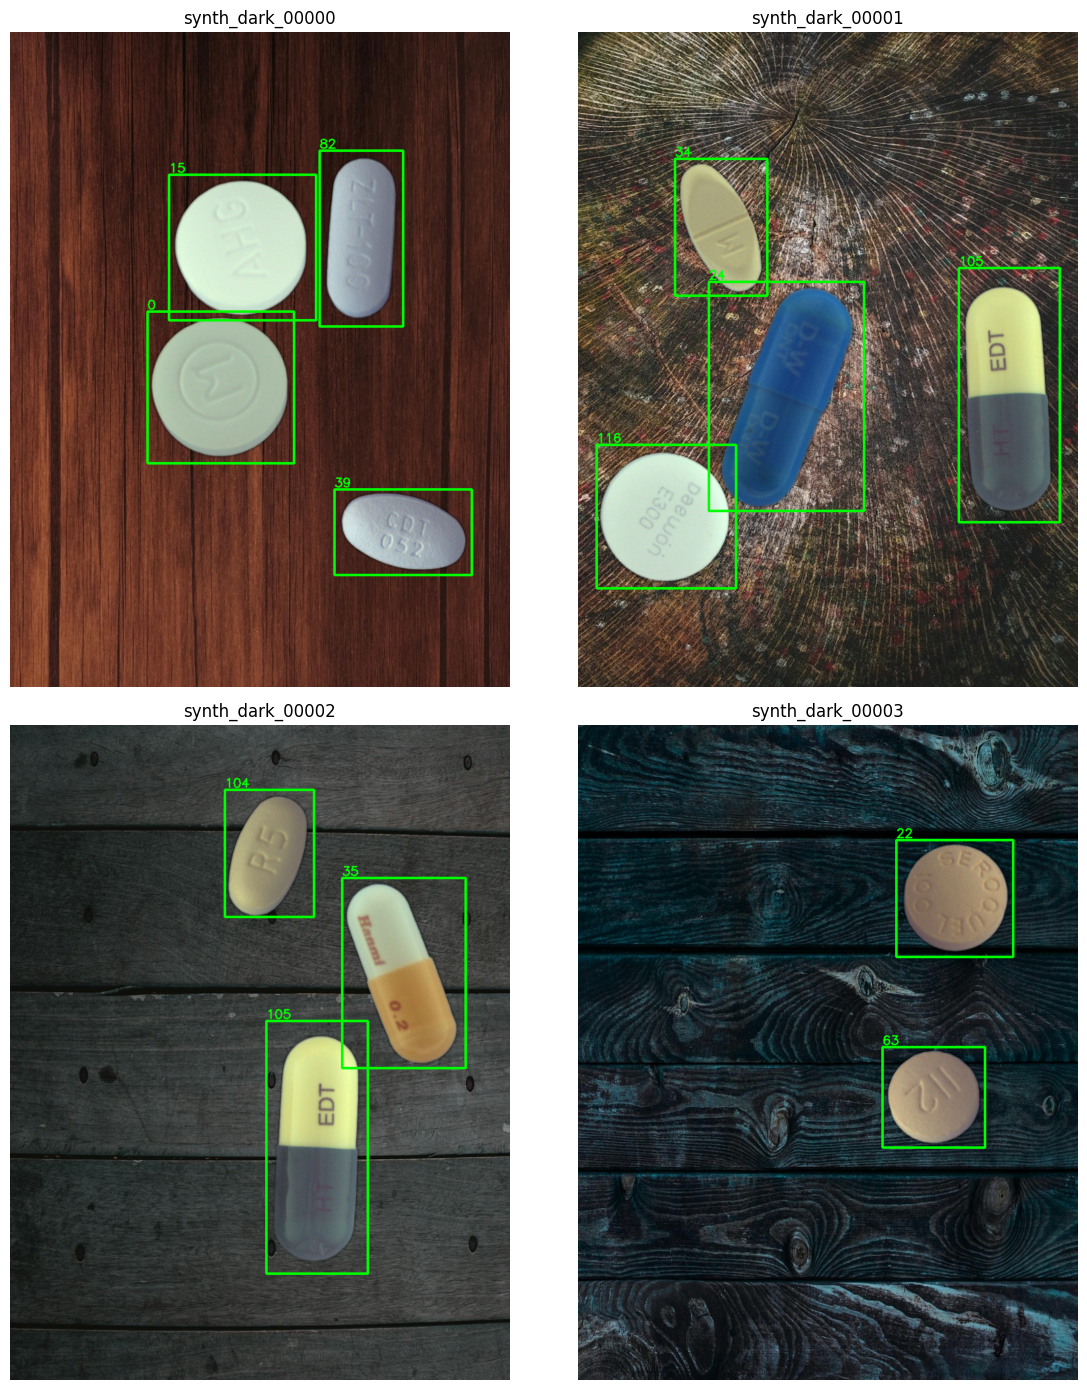

In [18]:
import matplotlib.pyplot as plt

sample_imgs = sorted(SYNTH_IMG_DIR.glob("*.jpg"))[:4]

if sample_imgs:
    fig, axes = plt.subplots(2, 2, figsize=(12, 14))
    for ax, img_path in zip(axes.flat, sample_imgs):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

        # 라벨 박스 오버레이
        lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
        if lbl_path.exists():
            h, w = img.shape[:2]
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    cls, cx, cy, bw, bh = parts[0], *map(float, parts[1:5])
                    x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                    x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                    cv2.putText(img, cls, (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        ax.imshow(img)
        ax.set_title(img_path.stem)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("생성된 이미지 없음")